In [ ]:
#MLP = Multi Layer Perceptron
import sklearn.neural_network as nn
import sklearn.datasets as ds
import matplotlib.pyplot as plt


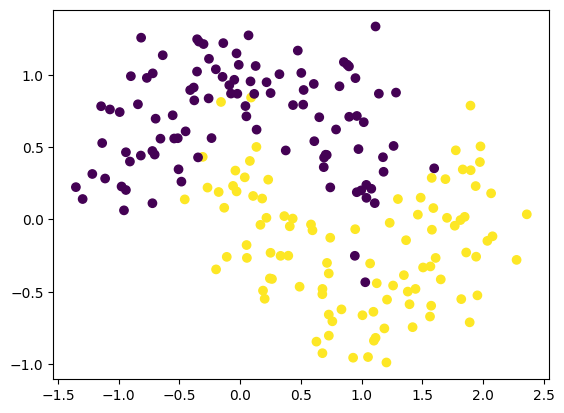

In [ ]:
x,y = ds.make_moons(n_samples=200, noise=0.25,random_state=3)
plt.scatter(x[:,0],x[:,1],c=y)
plt.show()

In [ ]:
# solver : 경사하강알고리즘
# lbfgs - 속도가 빠르고 적은 데이터에 최적화
# sgd - 데이터가 많은경우, learning_rate 의 세밀한 조정이 가능, 가중치를 점진적으로 갱신, 속도가 느림
# adam - 기본값, 사용이 쉽고 데부분의 데이터에서 안정적인 속도와 성능
# max_iter = 최대 반복 횟수
# hidden_layer_sizes = (5,2) : 퍼셉트론 5개 짜리 히든레이어 1개, 퍼셉트론 2개 짜리 히든레이어 1개
# 기본 : (100,) -> 퍼셉트론 100 개 짜리 히든레이어 1개
# 10 짜리 퍼셉트론 히든레이어가 2개
# 그럼 퍼셉트론 5개 짜리 히든레이어 100개는 어떻게 만드나? -> 5개 이상은 만들지 않는것으로 제한
# 최대 가능 레이어 생성 -> (5,5,5,5,5)
model = nn.MLPClassifier(solver='lbfgs',random_state=0,max_iter=100000,hidden_layer_sizes=(1,)).fit(x,y)


In [ ]:
def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1], c=y)
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

[1 1 1 ... 0 0 0]


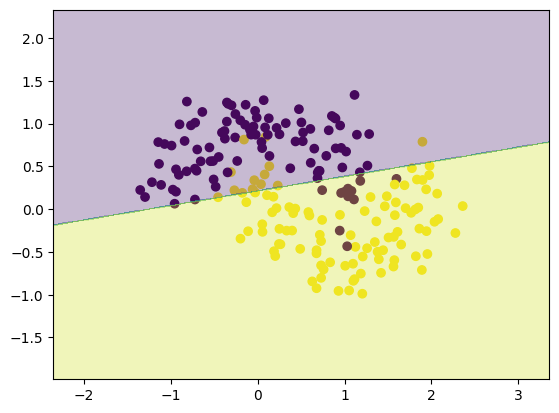

In [ ]:
import numpy as np
draw_area(x,y,model)

[1 1 1 ... 1 1 1]


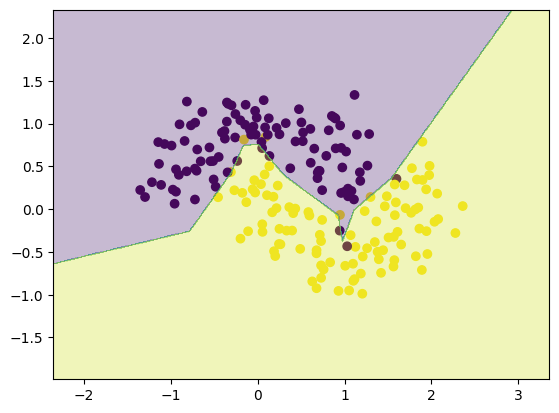

In [ ]:
#퍼셉트론 10개 ->10개의 직선을 이용해 결정경계를 생성
model = nn.MLPClassifier(solver='lbfgs',random_state=0,max_iter=100000,hidden_layer_sizes=(10,)).fit(x,y)
draw_area(x,y,model)

[1 1 1 ... 1 1 1]


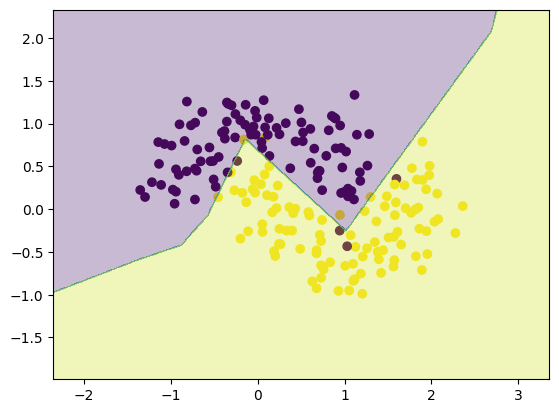

In [ ]:
#퍼셉트론 10개,은닉층10개 ->10개의 직선을 이용해 결정경계를 생성,은닉층을 통해서 곡선화
#은닉층을 통해 경계면을 매끄럽게 만든다,
model = nn.MLPClassifier(solver='lbfgs',random_state=0,max_iter=100000,hidden_layer_sizes=(10,10)).fit(x,y)
draw_area(x,y,model)

[1 1 1 ... 1 1 1]


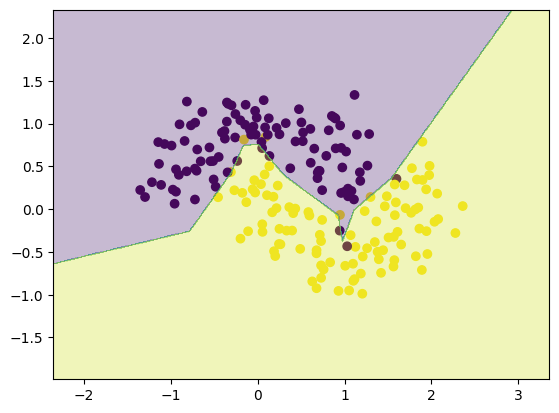

In [ ]:
model = nn.MLPClassifier(solver='lbfgs',random_state=0,max_iter=100000,hidden_layer_sizes=(10,)).fit(x,y)
draw_area(x,y,model)#20개의 뉴런은 10개보다 더 많은 비선형 조합을 만들어낼 수 있어서 더 복잡한 결정 경계를 생성할 수 있습니다.
#hidden_layer_sizes=(10,)->부드럽고 단순함
#hidden_layer_sizes=(20,)->퍼셉트론은 더 복잡하고 세밀한 경계,작은 굴곡이나 영역도 더 잘 따라가려함

[0 0 0 ... 1 1 1]


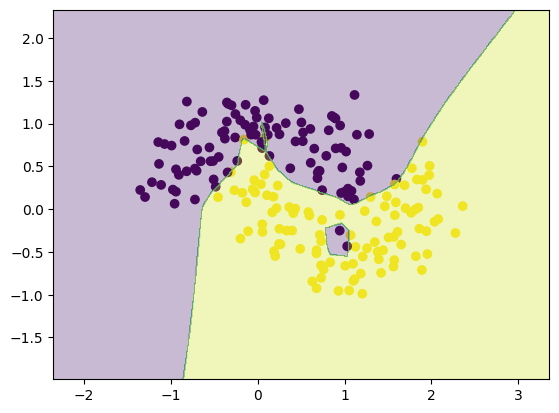

In [ ]:
model = nn.MLPClassifier(solver='lbfgs',random_state=0,max_iter=100000,hidden_layer_sizes=(50,100)).fit(x,y)
draw_area(x,y,model)#(1, 30)은 (1, 20)보다 조금 더 복잡한 결정 경계를 만들 수 있지만
#첫 번째 층이 1개 뉴런이라 정보 병목이 발생해 크게 차이가 안 날 가능성있음
#은닉층이 많아지면 결정경계가 부드러워진다.(SVM에서 커널효과를낸다-비선형 구조에 가깝게)